# Banka Telefon Pazarlamasında Vadeli Mevduat Aboneliği Tahmini

**TNC Group — Makine Öğrenmesi ile Probleme Uygun Çözüm Geliştirme** · Hazırlayan: Elif DELAL

**Problem:** Bir banka, vadeli mevduat ürününü telefonla pazarlamaktadır. Her arama zaman ve personel maliyeti
doğurur; müşterilerin yalnızca ~%11'i ürünü almaktadır. Bu çalışmada müşterinin demografik bilgileri, geçmiş
kampanya geçmişi ve aramanın yapıldığı dönemin ekonomik göstergeleri kullanılarak **arama yapılmadan önce**
müşterinin vadeli mevduata abone olup olmayacağı (evet/hayır) tahmin edilir. Böylece arama listesi, olasılığı
en yüksek müşterilerden başlanarak sıralanabilir.

**Veri seti:** UCI Machine Learning Repository — *Bank Marketing* (bank-additional-full.csv),
Moro, Cortez & Rita (2014). Lisans: CC BY 4.0.
<https://archive.ics.uci.edu/dataset/222/bank+marketing>

**İçerik:** 1) Veri yükleme · 2) Veri keşfi · 3) Ön işleme · 4) Modeller ve hiperparametre arama ·
5) Eşik seçimi · 6) Test değerlendirmesi · 7) Hata analizi · 8) Zaman bazlı doğrulama · 9) Sonuç

In [1]:
import json, os, time, urllib.request, zipfile, io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("grafikler", exist_ok=True)
os.makedirs("sonuclar", exist_ok=True)

# Grafik stili: sade eksenler, silik ızgara, sabit renk sırası (mavi, turuncu, camgöbeği)
MAVI, TURUNCU, CAMGOBEGI, GRI = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
METIN, METIN2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae",
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": METIN, "axes.titlelocation": "left",
    "axes.labelcolor": METIN2, "xtick.color": METIN2, "ytick.color": METIN2, "legend.frameon": False,
})

def yuzde(x, basamak=1):
    return f"%{x * 100:.{basamak}f}".replace(".", ",")

## 1. Veri Setinin Yüklenmesi

In [2]:
VERI = "veri/bank-additional-full.csv"
if not os.path.exists(VERI):  # Colab'da dosya yoksa UCI'den indir
    os.makedirs("veri", exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    dis = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    ic = zipfile.ZipFile(io.BytesIO(dis.read("bank-additional.zip")))
    with open(VERI, "wb") as f:
        f.write(ic.read("bank-additional/bank-additional-full.csv"))

df_ham = pd.read_csv(VERI, sep=";")
print("Boyut:", df_ham.shape)
df_ham.head()

Boyut: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
sayisal = df_ham.select_dtypes(include="number").columns.tolist()
kategorik = [c for c in df_ham.columns if c not in sayisal and c != "y"]
print("Sayısal değişkenler   :", sayisal)
print("Kategorik değişkenler :", kategorik)
print("\nBoş (NaN) hücre sayısı:", int(df_ham.isna().sum().sum()))
print("Tekrarlanan satır sayısı:", int(df_ham.duplicated().sum()))

bilinmeyen = (df_ham[kategorik] == "unknown").sum()
bilinmeyen = bilinmeyen[bilinmeyen > 0].sort_values(ascending=False)
print("\n'unknown' (eksik) değer sayıları:")
print(pd.DataFrame({"adet": bilinmeyen, "oran": (bilinmeyen / len(df_ham)).map(yuzde)}))

print("\nHedef dağılımı (y):")
print(df_ham["y"].value_counts().to_frame("adet").assign(oran=lambda t: (t["adet"] / len(df_ham)).map(yuzde)))

Sayısal değişkenler   : ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Kategorik değişkenler : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Boş (NaN) hücre sayısı: 0
Tekrarlanan satır sayısı: 12

'unknown' (eksik) değer sayıları:
           adet   oran
default    8597  %20,9
education  1731   %4,2
housing     990   %2,4
loan        990   %2,4
job         330   %0,8
marital      80   %0,2

Hedef dağılımı (y):
      adet   oran
y                
no   36548  %88,7
yes   4640  %11,3


In [4]:
df_ham[sayisal].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


## 2. Veri Keşfi (EDA)

Aşağıdaki grafiklerde her kategori için **abone olma oranı** (y = "yes" olanların payı) gösterilmiştir.
Kesikli çizgi genel ortalamayı (%11,3) belirtir.

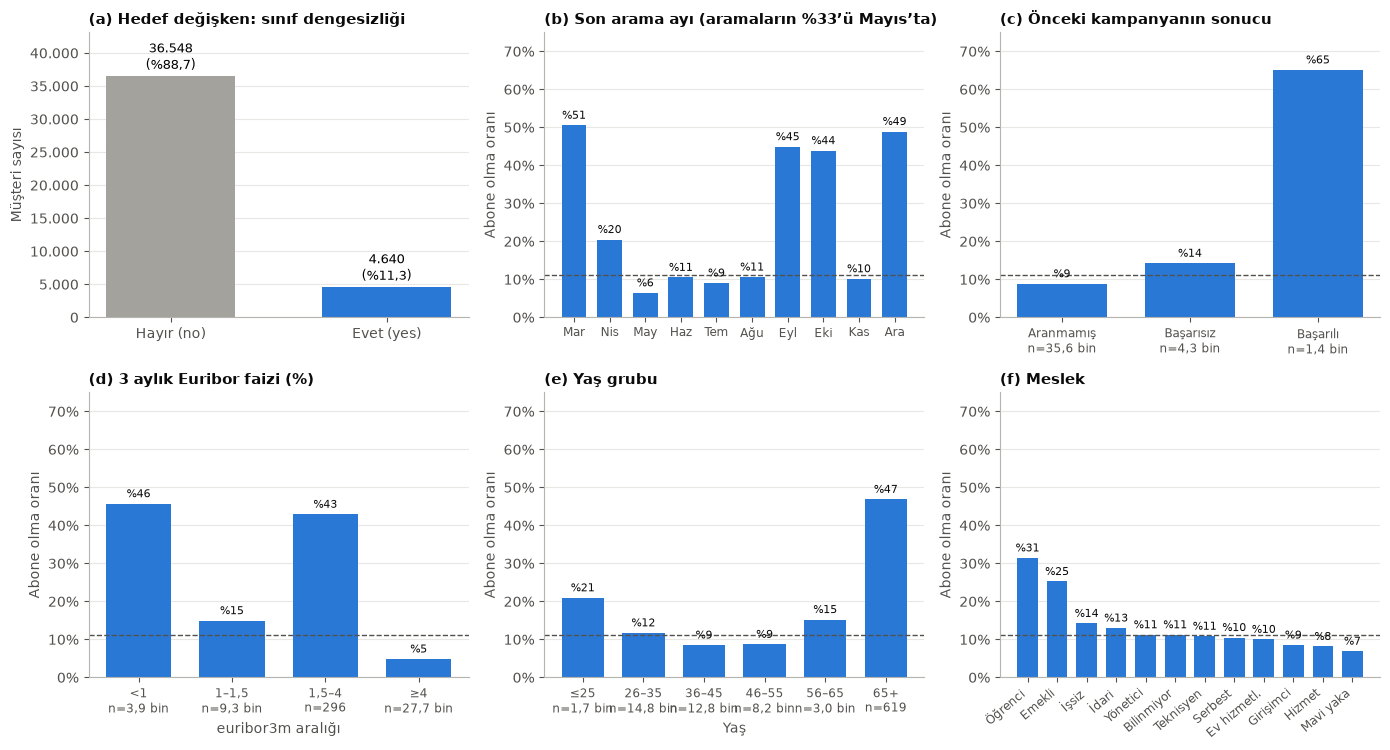

Aylık oran ve hacim:
         mean   size
month              
mar    %50,5    546
apr    %20,5   2632
may     %6,4  13769
jun    %10,5   5318
jul     %9,0   7174
aug    %10,6   6178
sep    %44,9    570
oct    %43,9    718
nov    %10,1   4101
dec    %48,9    182

Önceki kampanya:
               mean   size
poutcome                 
nonexistent   %8,8  35563
failure      %14,2   4252
success      %65,1   1373

Euribor:
                mean   size
euribor_grup              
<1            %45,7   3908
1–1,5         %14,9   9308
1,5–4         %42,9    296
≥4             %4,8  27676


In [5]:
df = df_ham.copy()
df["hedef"] = (df["y"] == "yes").astype(int)
genel_oran = df["hedef"].mean()

def kisa_n(n):
    return f"{n / 1000:.1f} bin".replace(".", ",") if n >= 1000 else str(n)

def oran_grafigi(ax, seri, sira, etiketler, baslik, renk=MAVI, dondur=0, n_goster=True):
    ozet = df.groupby(seri, observed=True)["hedef"].agg(["mean", "size"]).reindex(sira)
    x = np.arange(len(ozet))
    ax.bar(x, ozet["mean"], color=renk, width=0.7)
    ax.axhline(genel_oran, color=METIN2, lw=1, ls="--")
    for xi, o in zip(x, ozet["mean"]):
        ax.text(xi, o + 0.01, f"%{o*100:.0f}", ha="center", va="bottom", fontsize=8, color=METIN)
    if n_goster:  # örnek sayısı (n) etiketin altına yazılır
        etiketler = [f"{e}\nn={kisa_n(n)}" for e, n in zip(etiketler, ozet["size"])]
    ax.set_xticks(x, etiketler, rotation=dondur, ha="right" if dondur else "center", fontsize=8.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_ylabel("Abone olma oranı")
    ax.set_title(baslik)
    ax.grid(axis="x", visible=False)
    return ozet

fig, eksen = plt.subplots(2, 3, figsize=(14, 7.6))

# (a) Hedef dağılımı
ax = eksen[0, 0]
sayim = df["y"].value_counts().reindex(["no", "yes"])
ax.bar(["Hayır (no)", "Evet (yes)"], sayim.values, color=[GRI, MAVI], width=0.6)
for i, v in enumerate(sayim.values):
    ax.text(i, v + 400, f"{v:,}".replace(",", ".") + f"\n({yuzde(v / len(df))})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, sayim.max() * 1.18)
ax.set_ylabel("Müşteri sayısı")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
ax.set_title("(a) Hedef değişken: sınıf dengesizliği")
ax.grid(axis="x", visible=False)

# (b) Ay
aylar = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
ay_tr = ["Mar", "Nis", "May", "Haz", "Tem", "Ağu", "Eyl", "Eki", "Kas", "Ara"]
ay_ozet = oran_grafigi(eksen[0, 1], "month", aylar, ay_tr, "(b) Son arama ayı (aramaların %33’ü Mayıs’ta)", n_goster=False)

# (c) Önceki kampanya sonucu
po_ozet = oran_grafigi(eksen[0, 2], "poutcome", ["nonexistent", "failure", "success"],
                       ["Aranmamış", "Başarısız", "Başarılı"], "(c) Önceki kampanyanın sonucu")

# (d) Euribor 3 aylık faiz
EU = ["<1", "1–1,5", "1,5–4", "≥4"]
df["euribor_grup"] = pd.cut(df["euribor3m"], [0, 1, 1.5, 4, 6], labels=EU)
eu_ozet = oran_grafigi(eksen[1, 0], "euribor_grup", EU, EU, "(d) 3 aylık Euribor faizi (%)")
eksen[1, 0].set_xlabel("euribor3m aralığı")

# (e) Yaş grubu
df["yas_grup"] = pd.cut(df["age"], [0, 25, 35, 45, 55, 65, 120], labels=["≤25", "26–35", "36–45", "46–55", "56–65", "65+"])
yas_ozet = oran_grafigi(eksen[1, 1], "yas_grup", ["≤25", "26–35", "36–45", "46–55", "56–65", "65+"],
                        ["≤25", "26–35", "36–45", "46–55", "56–65", "65+"], "(e) Yaş grubu")
eksen[1, 1].set_xlabel("Yaş")

# (f) Meslek
meslek_tr = {"student": "Öğrenci", "retired": "Emekli", "unemployed": "İşsiz", "admin.": "İdari",
             "management": "Yönetici", "unknown": "Bilinmiyor", "technician": "Teknisyen", "self-employed": "Serbest",
             "housemaid": "Ev hizmetl.", "entrepreneur": "Girişimci", "services": "Hizmet", "blue-collar": "Mavi yaka"}
meslek_sira = df.groupby("job")["hedef"].mean().sort_values(ascending=False).index.tolist()
meslek_ozet = oran_grafigi(eksen[1, 2], "job", meslek_sira, [meslek_tr[m] for m in meslek_sira], "(f) Meslek", dondur=40, n_goster=False)

for ax in eksen.flat[1:]:
    ax.set_ylim(0, 0.75)
fig.tight_layout()
fig.savefig("grafikler/1_veri_kesfi.png")
plt.show()

print("Aylık oran ve hacim:\n", ay_ozet.assign(mean=lambda t: t["mean"].map(yuzde)))
print("\nÖnceki kampanya:\n", po_ozet.assign(mean=lambda t: t["mean"].map(yuzde)))
print("\nEuribor:\n", eu_ozet.assign(mean=lambda t: t["mean"].map(yuzde)))

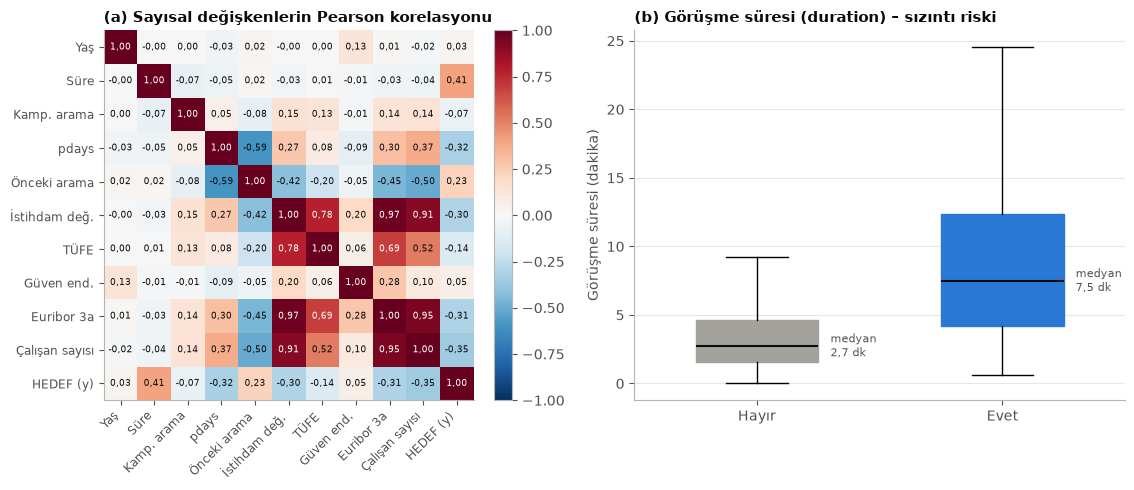

nr.employed      -0.355
pdays            -0.325
euribor3m        -0.308
emp.var.rate     -0.298
cons.price.idx   -0.136
campaign         -0.066
age               0.030
cons.conf.idx     0.055
previous          0.230
duration          0.405
Name: hedef, dtype: float64

Ekonomik göstergeler arası korelasyon:
               emp.var.rate  euribor3m  nr.employed
emp.var.rate         1.000      0.972        0.907
euribor3m            0.972      1.000        0.945
nr.employed          0.907      0.945        1.000


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.35, 1]})

# (a) Sayısal değişkenler arası korelasyon
etiket = {"age": "Yaş", "duration": "Süre", "campaign": "Kamp. arama", "pdays": "pdays", "previous": "Önceki arama",
          "emp.var.rate": "İstihdam değ.", "cons.price.idx": "TÜFE", "cons.conf.idx": "Güven end.",
          "euribor3m": "Euribor 3a", "nr.employed": "Çalışan sayısı", "hedef": "HEDEF (y)"}
kor = df[sayisal + ["hedef"]].corr()
im = ax1.imshow(kor.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax1.set_xticks(range(len(kor)), [etiket[c] for c in kor.columns], rotation=45, ha="right", fontsize=8.5)
ax1.set_yticks(range(len(kor)), [etiket[c] for c in kor.columns], fontsize=8.5)
for i in range(len(kor)):
    for j in range(len(kor)):
        v = kor.values[i, j]
        ax1.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=6.8,
                 color="white" if abs(v) > 0.6 else METIN)
ax1.grid(False)
ax1.set_title("(a) Sayısal değişkenlerin Pearson korelasyonu")
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.03)

# (b) Görüşme süresi – hedef ilişkisi (veri sızıntısı)
gruplar = [df.loc[df["hedef"] == 0, "duration"] / 60, df.loc[df["hedef"] == 1, "duration"] / 60]
kutu = ax2.boxplot(gruplar, tick_labels=["Hayır", "Evet"], showfliers=False, widths=0.5, patch_artist=True,
                   medianprops={"color": METIN, "lw": 1.5})
for parca, renk in zip(kutu["boxes"], [GRI, MAVI]):
    parca.set_facecolor(renk); parca.set_edgecolor(renk)
for i, g in enumerate(gruplar, start=1):
    ax2.text(i + 0.3, g.median(), f"medyan\n{g.median():.1f} dk".replace(".", ","), va="center", fontsize=8, color=METIN2)
ax2.set_ylabel("Görüşme süresi (dakika)")
ax2.set_title("(b) Görüşme süresi (duration) – sızıntı riski")
ax2.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("grafikler/2_korelasyon_sure.png")
plt.show()

print(kor["hedef"].drop("hedef").sort_values().round(3))
print("\nEkonomik göstergeler arası korelasyon:\n", kor.loc[["emp.var.rate", "euribor3m", "nr.employed"], ["emp.var.rate", "euribor3m", "nr.employed"]].round(3))

**Gözlemler**

1. **Sınıf dengesizliği:** Müşterilerin yalnızca ~%11,3'ü abone olmuştur. "Herkese hayır" diyen bir model
   %88,7 doğruluk elde eder; bu yüzden doğruluk (accuracy) tek başına yanıltıcıdır → precision, recall, F1 ve
   PR-AUC kullanılacaktır.
2. **Dönem etkisi çok güçlüdür:** Mayıs ayında aramaların ~%33'ü yapılmış ama oran yalnızca ~%6,4'tür; mart,
   eylül, ekim ve aralıkta oran %44–51'e çıkar. Benzer şekilde Euribor faizi 1'in altındayken oran %46, 4'ün
   üstündeyken yalnızca %5'tir. Bu değişkenler müşteriden çok **kampanyanın yapıldığı ekonomik dönemi** temsil eder.
3. **Geçmiş başarı en güçlü müşteri sinyalidir:** Önceki kampanyada ürünü almış müşterilerin ~%65'i yeniden abone olmuştur.
4. **Yaş ve meslek:** 25 yaş altı (öğrenciler) ve 65 yaş üstü (emekliler) grupları ortalamanın çok üzerindedir;
   ilişki doğrusal değil, U biçimlidir.
5. **Çoklu doğrusallık:** `emp.var.rate`, `euribor3m` ve `nr.employed` arasında 0,90+ korelasyon vardır;
   doğrusal modelde katsayı yorumunu zorlaştırır.
6. **Veri sızıntısı:** `duration` (görüşme süresi) hedefle en yüksek korelasyona sahiptir ancak arama bitmeden
   bilinemez. Gerçekçi bir model için **çıkarılacak**, yalnızca karşılaştırma (benchmark) amacıyla kullanılacaktır.

## 3. Veri Ön İşleme

In [7]:
veri = df_ham.drop_duplicates().reset_index(drop=True)          # 12 tekrar eden satır
print("Tekrarlar silindi:", len(df_ham), "->", len(veri))

veri["hedef"] = (veri["y"] == "yes").astype(int)
veri["onceden_arandi"] = (veri["pdays"] != 999).astype(int)      # pdays=999 'hiç aranmamış' kodu
veri = veri.drop(columns=["y", "pdays"])

SIZINTI = ["duration"]
KATEGORIK = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
SAYISAL = ["age", "campaign", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m",
           "nr.employed", "onceden_arandi"]
OZELLIKLER = KATEGORIK + SAYISAL

X = veri[OZELLIKLER + SIZINTI]
y = veri["hedef"]
X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

# Aykırı değer: kampanya arama sayısı (max 56) eğitim setinin 99. yüzdeliğinde kırpılır
UST_SINIR = float(X_egitim["campaign"].quantile(0.99))
X_egitim = X_egitim.assign(campaign=X_egitim["campaign"].clip(upper=UST_SINIR))
X_test = X_test.assign(campaign=X_test["campaign"].clip(upper=UST_SINIR))
print(f"campaign üst sınırı (99. yüzdelik): {UST_SINIR:.0f}  | orijinal maksimum: {veri['campaign'].max()}")

print(f"Eğitim: {len(X_egitim):,} satır (pozitif oran {yuzde(y_egitim.mean(), 2)})")
print(f"Test  : {len(X_test):,} satır (pozitif oran {yuzde(y_test.mean(), 2)})")

def on_isleme(sayisal=SAYISAL):
    return ColumnTransformer([
        ("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), KATEGORIK),
        ("say", StandardScaler(), sayisal),
    ])

ornek = on_isleme().fit(X_egitim[OZELLIKLER])
print("One-hot + ölçekleme sonrası özellik sayısı:", len(ornek.get_feature_names_out()))

Tekrarlar silindi: 41188 -> 41176
campaign üst sınırı (99. yüzdelik): 14  | orijinal maksimum: 56
Eğitim: 32,940 satır (pozitif oran %11,27)
Test  : 8,236 satır (pozitif oran %11,27)


One-hot + ölçekleme sonrası özellik sayısı: 62


Uygulanan adımlar:

* **Tekrarlı satırlar** silindi (12 satır).
* **Eksik değerler:** Veride NaN yoktur; eksikler `unknown` etiketiyle kodlanmıştır. Özellikle `default`
  sütununda %21 oranında olduğundan ve "bilinmiyor" bilgisinin kendisi anlamlı olabileceğinden ayrı bir
  kategori olarak bırakılmıştır (silme, verinin %25'ini kaybettirirdi).
* **`pdays`** sütunundaki 999 değeri gerçek bir gün sayısı değil "hiç aranmadı" kodudur; ölçeklemeyi bozmaması için
  ikili `onceden_arandi` özelliğine dönüştürülmüştür.
* **`duration`** sızıntı nedeniyle model girdilerinden çıkarılmıştır (yalnızca karşılaştırma için tutulur).
* **Aykırı değer:** `campaign` (bu kampanyada yapılan arama sayısı) sağa çok çarpıktır (maks. 56); eğitim
  setinin 99. yüzdeliğinde kırpılmıştır. Sınır yalnızca eğitim setinden hesaplanır.
* **Encoding:** 10 kategorik değişken One-Hot Encoding ile sayısallaştırılmıştır.
* **Ölçekleme:** Sayısal değişkenler StandardScaler ile standartlaştırılmıştır (Lojistik Regresyon için gerekli).
* **Veri bölme:** %80 eğitim / %20 test, sınıf oranını koruyan **tabakalı (stratified)** bölme. Hiperparametre
  ve eşik seçimi yalnızca eğitim setinde 5 katlı çapraz doğrulama ile yapılır; test seti en sona saklanır.
  Tüm dönüşümler `Pipeline` içinde olduğundan çapraz doğrulamada da sızıntı oluşmaz.

## 4. Modeller ve Hiperparametre Arama

| Model | Rolü | Seçim gerekçesi |
|---|---|---|
| Dummy (çoğunluk sınıfı) | Alt sınır | Modelin gerçekten bir şey öğrenip öğrenmediğini görmek |
| Lojistik Regresyon | Temel model | Hızlı, yorumlanabilir, olasılık çıktısı iyi kalibre |
| Random Forest | Doğrusal olmayan model | Etkileşimleri ve U biçimli ilişkileri (yaş) yakalar, aykırı değerlere dayanıklı |
| HistGradientBoosting | Güçlü topluluk modeli | Tablo verilerinde genellikle en iyi sonuç; büyük veride hızlı |

Dengesizlik için `class_weight` (sınıf ağırlıklandırma) parametresi arama uzayına eklenmiştir. Seçim ölçütü
**Ortalama Kesinlik (PR-AUC / average precision)**'tır; nadir pozitif sınıfı sıralama başarısını doğrudan ölçer.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
Xe = X_egitim[OZELLIKLER]

aramalar = {
    "Lojistik Regresyon": GridSearchCV(
        Pipeline([("on", on_isleme()), ("model", LogisticRegression(max_iter=3000))]),
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
        scoring="average_precision", cv=cv, n_jobs=-1),
    "Random Forest": RandomizedSearchCV(
        Pipeline([("on", on_isleme()), ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
        {"model__max_depth": [8, 12, 16, None], "model__min_samples_leaf": [5, 10, 20, 40],
         "model__max_features": ["sqrt", 0.3], "model__class_weight": [None, "balanced_subsample"]},
        n_iter=12, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": RandomizedSearchCV(
        Pipeline([("on", on_isleme()), ("model", HistGradientBoostingClassifier(max_iter=400, early_stopping=True,
                                                                                 validation_fraction=0.1, random_state=SEED))]),
        {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_leaf_nodes": [15, 31, 63],
         "model__min_samples_leaf": [20, 50, 100], "model__l2_regularization": [0.0, 1.0],
         "model__class_weight": [None, "balanced"]},
        n_iter=15, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1),
}

en_iyi, cv_sonuc = {}, {}
for ad, arama in aramalar.items():
    t0 = time.time()
    arama.fit(Xe, y_egitim)
    en_iyi[ad] = arama.best_estimator_
    i = arama.best_index_
    cv_sonuc[ad] = {"cv_pr_auc": float(arama.best_score_), "cv_std": float(arama.cv_results_["std_test_score"][i]),
                    "parametreler": {k.replace("model__", ""): v for k, v in arama.best_params_.items()},
                    "sure_sn": round(time.time() - t0, 1)}
    print(f"{ad:22s} CV PR-AUC = {arama.best_score_:.4f} ± {cv_sonuc[ad]['cv_std']:.4f} | "
          f"{cv_sonuc[ad]['parametreler']} | {cv_sonuc[ad]['sure_sn']} sn")

en_iyi["Dummy"] = Pipeline([("on", on_isleme()), ("model", DummyClassifier(strategy="most_frequent"))]).fit(Xe, y_egitim)

Lojistik Regresyon     CV PR-AUC = 0.4514 ± 0.0142 | {'C': 1, 'class_weight': None} | 14.9 sn


Random Forest          CV PR-AUC = 0.4680 ± 0.0167 | {'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 8, 'class_weight': None} | 94.2 sn


HistGradientBoosting   CV PR-AUC = 0.4681 ± 0.0160 | {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'learning_rate': 0.05, 'l2_regularization': 0.0, 'class_weight': None} | 23.0 sn


## 5. Karar Eşiği Seçimi

Modeller bir **olasılık** üretir; varsayılan 0,5 eşiği dengesiz veride çoğu pozitifi kaçırır (ya da
`class_weight=balanced` ile çok fazla yanlış alarm üretir). Eşik, **test setine bakmadan**, eğitim setindeki
5 katlı çapraz doğrulamanın katman dışı (out-of-fold) tahminleri üzerinde F1'i en yüksek yapan değer olarak seçilmiştir.

In [9]:
esikler = {}
for ad in ["Lojistik Regresyon", "Random Forest", "HistGradientBoosting"]:
    oof = cross_val_predict(en_iyi[ad], Xe, y_egitim, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(y_egitim, oof)
    f1 = 2 * p * r / (p + r + 1e-12)
    k = int(np.nanargmax(f1[:-1]))
    esikler[ad] = float(t[k])
    print(f"{ad:22s} seçilen eşik = {t[k]:.3f}  (OOF F1 = {f1[k]:.3f}, P = {p[k]:.3f}, R = {r[k]:.3f})")
esikler["Dummy"] = 0.5

Lojistik Regresyon     seçilen eşik = 0.206  (OOF F1 = 0.485, P = 0.434, R = 0.548)


Random Forest          seçilen eşik = 0.168  (OOF F1 = 0.501, P = 0.436, R = 0.590)


HistGradientBoosting   seçilen eşik = 0.203  (OOF F1 = 0.500, P = 0.444, R = 0.571)


## 6. Test Seti Değerlendirmesi

In [10]:
def degerlendir(model, X_, y_, esik):
    olas = model.predict_proba(X_)[:, 1]
    tahmin = (olas >= esik).astype(int)
    return {"Accuracy": accuracy_score(y_, tahmin), "Precision": precision_score(y_, tahmin, zero_division=0),
            "Recall": recall_score(y_, tahmin), "F1": f1_score(y_, tahmin),
            "ROC-AUC": roc_auc_score(y_, olas), "PR-AUC": average_precision_score(y_, olas)}, olas, tahmin

Xt = X_test[OZELLIKLER]
sonuclar, olasiliklar, tahminler = {}, {}, {}
for ad in ["Dummy", "Lojistik Regresyon", "Random Forest", "HistGradientBoosting"]:
    sonuclar[ad], olasiliklar[ad], tahminler[ad] = degerlendir(en_iyi[ad], Xt, y_test, esikler[ad])
    if ad != "Dummy":  # karşılaştırma: varsayılan 0,5 eşiği
        sonuclar[ad + " (eşik 0,5)"] = degerlendir(en_iyi[ad], Xt, y_test, 0.5)[0]

# Benchmark: duration dahil (gerçekçi değil – arama bitmeden bilinemez)
hgb_param = {k.replace("model__", ""): v for k, v in aramalar["HistGradientBoosting"].best_params_.items()}
sure_model = Pipeline([("on", on_isleme(SAYISAL + SIZINTI)),
                       ("model", HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=0.1,
                                                                random_state=SEED, **hgb_param))])
sure_model.fit(X_egitim, y_egitim)
oof_sure = cross_val_predict(sure_model, X_egitim, y_egitim, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
p, r, t = precision_recall_curve(y_egitim, oof_sure)
esik_sure = float(t[np.nanargmax((2 * p * r / (p + r + 1e-12))[:-1])])
sonuclar["HGB + duration (benchmark)"] = degerlendir(sure_model, X_test, y_test, esik_sure)[0]

tablo = pd.DataFrame(sonuclar).T
tablo["Eşik"] = [esikler.get(a.replace(" (eşik 0,5)", ""), np.nan) if "0,5" not in a else 0.5 for a in tablo.index]
tablo.loc["HGB + duration (benchmark)", "Eşik"] = esik_sure
tablo.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Eşik
Dummy,0.887,0.000,0.000,0.000,0.500,0.113,0.500
Lojistik Regresyon,0.874,0.453,0.578,0.508,0.800,0.454,0.206
"Lojistik Regresyon (eşik 0,5)",0.898,0.650,0.210,0.318,0.800,0.454,0.500
Random Forest,0.875,0.459,0.614,0.526,0.811,0.489,0.168
"Random Forest (eşik 0,5)",0.900,0.653,0.246,0.357,0.811,0.489,0.500
HistGradientBoosting,0.878,0.469,0.610,0.530,0.815,0.497,0.203
"HistGradientBoosting (eşik 0,5)",0.901,0.668,0.234,0.346,0.815,0.497,0.500
HGB + duration (benchmark),0.910,0.572,0.782,0.661,0.951,0.674,0.315


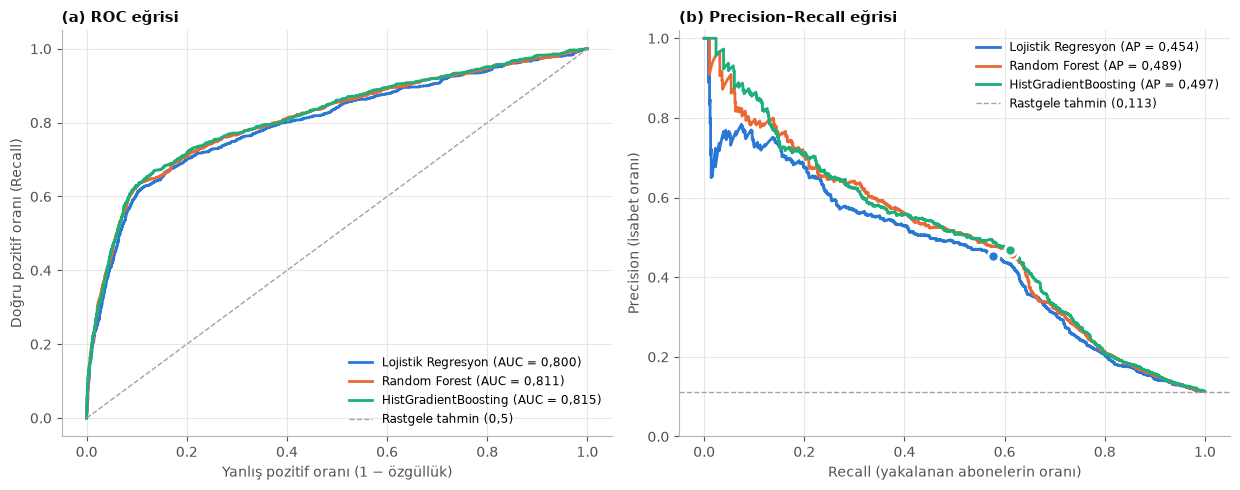

In [11]:
modeller3 = ["Lojistik Regresyon", "Random Forest", "HistGradientBoosting"]
renkler = dict(zip(modeller3, [MAVI, TURUNCU, CAMGOBEGI]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5))
for ad in modeller3:
    fpr, tpr, _ = roc_curve(y_test, olasiliklar[ad])
    ax1.plot(fpr, tpr, color=renkler[ad], lw=2, label=f"{ad} (AUC = {sonuclar[ad]['ROC-AUC']:.3f})".replace(".", ","))
    pr, rc, _ = precision_recall_curve(y_test, olasiliklar[ad])
    ax2.plot(rc, pr, color=renkler[ad], lw=2, label=f"{ad} (AP = {sonuclar[ad]['PR-AUC']:.3f})".replace(".", ","))
ax1.plot([0, 1], [0, 1], color=GRI, ls="--", lw=1, label="Rastgele tahmin (0,5)")
ax2.axhline(y_test.mean(), color=GRI, ls="--", lw=1, label=f"Rastgele tahmin ({y_test.mean():.3f})".replace(".", ","))
for ad in modeller3:  # seçilen eşikteki çalışma noktası
    ax2.plot(sonuclar[ad]["Recall"], sonuclar[ad]["Precision"], "o", ms=8, color=renkler[ad], mec="white", mew=2)
ax1.set(xlabel="Yanlış pozitif oranı (1 − özgüllük)", ylabel="Doğru pozitif oranı (Recall)", title="(a) ROC eğrisi")
ax2.set(xlabel="Recall (yakalanan abonelerin oranı)", ylabel="Precision (isabet oranı)", title="(b) Precision–Recall eğrisi", ylim=(0, 1.02))
ax1.legend(loc="lower right", fontsize=8.5); ax2.legend(loc="upper right", fontsize=8.5)
fig.tight_layout()
fig.savefig("grafikler/3_roc_pr.png")
plt.show()

PR-AUC'ye göre en iyi model: HistGradientBoosting


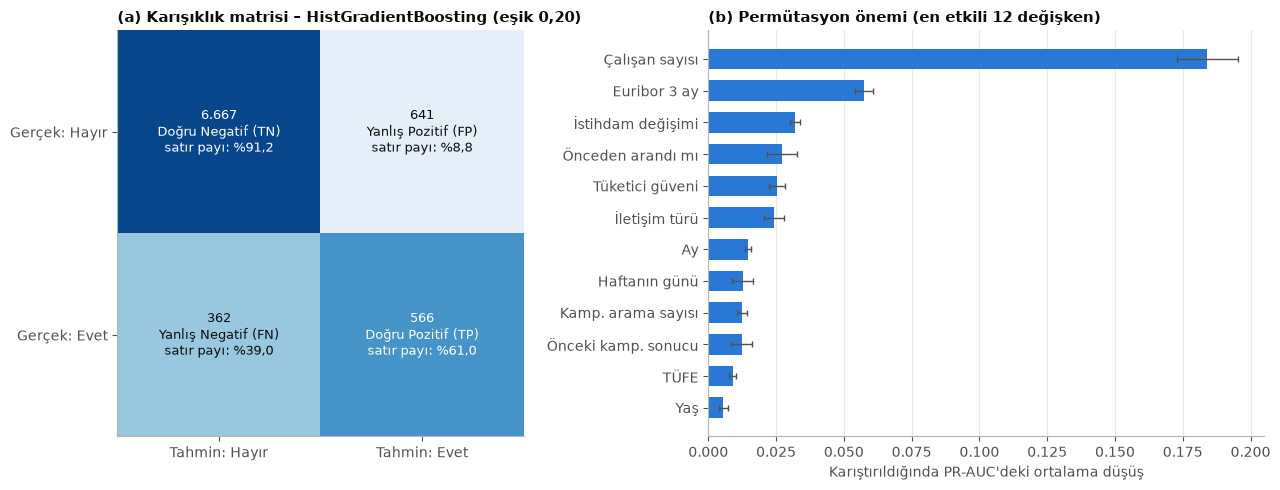

[[6667  641]
 [ 362  566]]
       ozellik     ort    std
   nr.employed  0.1841 0.0113
     euribor3m  0.0575 0.0032
  emp.var.rate  0.0320 0.0018
onceden_arandi  0.0272 0.0056
 cons.conf.idx  0.0253 0.0030
       contact  0.0242 0.0038
         month  0.0147 0.0012
   day_of_week  0.0127 0.0038
      campaign  0.0125 0.0018
      poutcome  0.0124 0.0039
cons.price.idx  0.0090 0.0014
           age  0.0056 0.0016
       default  0.0028 0.0017
      previous  0.0008 0.0003
       marital  0.0004 0.0004
     education  0.0001 0.0004
          loan -0.0001 0.0001
       housing -0.0001 0.0003
           job -0.0008 0.0006


In [12]:
EN_IYI = max(modeller3, key=lambda a: sonuclar[a]["PR-AUC"])
print("PR-AUC'ye göre en iyi model:", EN_IYI)

# Permütasyon önemi: her orijinal sütun karıştırıldığında test PR-AUC'si ne kadar düşüyor?
onem = permutation_importance(en_iyi[EN_IYI], Xt, y_test, scoring="average_precision", n_repeats=10,
                              random_state=SEED, n_jobs=-1)
onem_tr = {"job": "Meslek", "marital": "Medeni durum", "education": "Eğitim", "default": "Kredi temerrüdü",
           "housing": "Konut kredisi", "loan": "Bireysel kredi", "contact": "İletişim türü", "month": "Ay",
           "day_of_week": "Haftanın günü", "poutcome": "Önceki kamp. sonucu", "age": "Yaş", "campaign": "Kamp. arama sayısı",
           "previous": "Önceki arama sayısı", "emp.var.rate": "İstihdam değişimi", "cons.price.idx": "TÜFE",
           "cons.conf.idx": "Tüketici güveni", "euribor3m": "Euribor 3 ay", "nr.employed": "Çalışan sayısı",
           "onceden_arandi": "Önceden arandı mı"}
onem_df = pd.DataFrame({"ozellik": OZELLIKLER, "ort": onem.importances_mean, "std": onem.importances_std}).sort_values("ort")

cm = confusion_matrix(y_test, tahminler[EN_IYI])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})
oranli = cm / cm.sum(axis=1, keepdims=True)  # renk, satır oranına göre (sınıf başına başarı)
ax1.imshow(oranli, cmap="Blues", vmin=0, vmax=1)
adlar = [["Doğru Negatif (TN)", "Yanlış Pozitif (FP)"], ["Yanlış Negatif (FN)", "Doğru Pozitif (TP)"]]
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{cm[i, j]:,}".replace(",", ".") + f"\n{adlar[i][j]}\nsatır payı: {yuzde(oranli[i, j])}",
                 ha="center", va="center", fontsize=9.5, color="white" if oranli[i, j] > 0.5 else METIN)
ax1.set_xticks([0, 1], ["Tahmin: Hayır", "Tahmin: Evet"]); ax1.set_yticks([0, 1], ["Gerçek: Hayır", "Gerçek: Evet"])
ax1.grid(False)
ax1.set_title(f"(a) Karışıklık matrisi – {EN_IYI} (eşik {esikler[EN_IYI]:.2f})".replace(".", ","))

ust = onem_df.tail(12)
ax2.barh([onem_tr[o] for o in ust["ozellik"]], ust["ort"], xerr=ust["std"], color=MAVI, height=0.65,
         error_kw={"ecolor": METIN2, "lw": 1, "capsize": 2})
ax2.set_xlabel("Karıştırıldığında PR-AUC'deki ortalama düşüş")
ax2.set_title("(b) Permütasyon önemi (en etkili 12 değişken)")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("grafikler/4_karisiklik_onem.png")
plt.show()
print(cm)
print(onem_df.sort_values("ort", ascending=False).round(4).to_string(index=False))

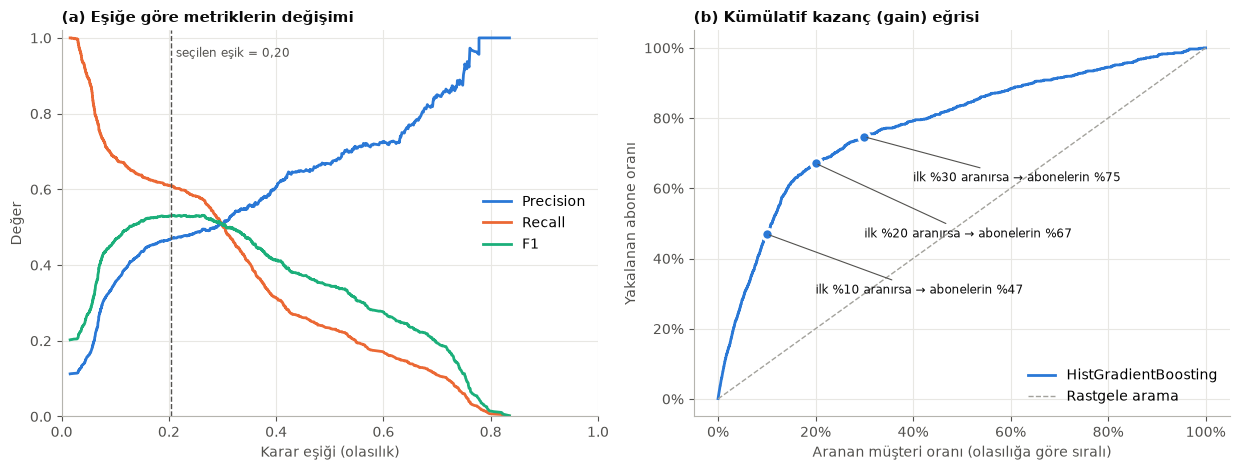

İlk %10 müşteri arandığında yakalanan abone oranı: %47,0 (lift = 4.70)
İlk %20 müşteri arandığında yakalanan abone oranı: %67,1 (lift = 3.36)
İlk %30 müşteri arandığında yakalanan abone oranı: %74,7 (lift = 2.49)


In [13]:
olas = olasiliklar[EN_IYI]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))

# (a) Eşiğe göre precision / recall / F1
pr, rc, th = precision_recall_curve(y_test, olas)
f1s = 2 * pr * rc / (pr + rc + 1e-12)
ax1.plot(th, pr[:-1], color=MAVI, lw=2, label="Precision")
ax1.plot(th, rc[:-1], color=TURUNCU, lw=2, label="Recall")
ax1.plot(th, f1s[:-1], color=CAMGOBEGI, lw=2, label="F1")
ax1.axvline(esikler[EN_IYI], color=METIN2, ls="--", lw=1)
ax1.text(esikler[EN_IYI] + 0.01, 0.95, f"seçilen eşik = {esikler[EN_IYI]:.2f}".replace(".", ","), fontsize=8.5, color=METIN2)
ax1.set(xlabel="Karar eşiği (olasılık)", ylabel="Değer", title="(a) Eşiğe göre metriklerin değişimi", xlim=(0, 1), ylim=(0, 1.02))
ax1.legend(loc="center right")

# (b) Kümülatif kazanç: olasılığa göre sıralı listede ilk %x aranırsa abonelerin ne kadarı yakalanır?
sira = np.argsort(-olas)
kazanc = np.cumsum(y_test.values[sira]) / y_test.sum()
pay = np.arange(1, len(olas) + 1) / len(olas)
ax2.plot(pay, kazanc, color=MAVI, lw=2, label=EN_IYI)
ax2.plot([0, 1], [0, 1], color=GRI, ls="--", lw=1, label="Rastgele arama")
kazanc_noktalari = {}
for q in [0.1, 0.2, 0.3]:
    v = float(kazanc[int(q * len(olas)) - 1]); kazanc_noktalari[q] = v
    ax2.plot(q, v, "o", color=MAVI, ms=8, mec="white", mew=2)
    ax2.annotate(f"ilk %{int(q*100)} aranırsa → abonelerin {yuzde(v, 0)}", (q, v), xytext={0.1: (0.2, 0.3), 0.2: (0.3, 0.46), 0.3: (0.4, 0.62)}[q],
                 fontsize=8.5, color=METIN, arrowprops={"arrowstyle": "-", "color": METIN2, "lw": 0.8})
ax2.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax2.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax2.set(xlabel="Aranan müşteri oranı (olasılığa göre sıralı)", ylabel="Yakalanan abone oranı", title="(b) Kümülatif kazanç (gain) eğrisi")
ax2.legend(loc="lower right")
fig.tight_layout()
fig.savefig("grafikler/5_esik_kazanc.png")
plt.show()
for q, v in kazanc_noktalari.items():
    print(f"İlk %{int(q*100)} müşteri arandığında yakalanan abone oranı: {yuzde(v)} (lift = {v / q:.2f})")

## 7. Hata Analizi

In [14]:
analiz = X_test.copy()
analiz["gercek"], analiz["tahmin"], analiz["olasilik"] = y_test.values, tahminler[EN_IYI], olas
analiz["durum"] = np.select(
    [(analiz.gercek == 1) & (analiz.tahmin == 1), (analiz.gercek == 0) & (analiz.tahmin == 1),
     (analiz.gercek == 1) & (analiz.tahmin == 0)], ["TP", "FP", "FN"], "TN")

profil = analiz.groupby("durum").agg(
    adet=("gercek", "size"), ort_olasilik=("olasilik", "mean"), euribor=("euribor3m", "mean"),
    onceden_arandi=("onceden_arandi", "mean"), cep_telefonu=("contact", lambda s: (s == "cellular").mean()),
    mayis=("month", lambda s: (s == "may").mean()), ort_sure_dk=("duration", lambda s: s.mean() / 60),
    ort_yas=("age", "mean")).reindex(["TP", "FN", "FP", "TN"])
print("Hata türlerine göre müşteri profili:")
display(profil.round(3))

def segment_recall(sutun, gruplar=None):
    t = analiz.assign(seg=gruplar if gruplar is not None else analiz[sutun])
    return t[t.gercek == 1].groupby("seg", observed=True).agg(abone=("gercek", "size"), recall=("tahmin", "mean"))

print("\nEuribor düzeyine göre recall (yakalanan abone oranı):")
display(segment_recall("euribor3m", pd.cut(analiz["euribor3m"], [0, 2, 4.5, 6], labels=["<2 (düşük faiz)", "2–4,5", ">4,5 (yüksek faiz)"])).round(3))
print("\nÖnceki kampanya sonucuna göre recall:")
display(segment_recall("poutcome").round(3))

# En emin olunan yanlışlar
print("\nModelin en emin olduğu yanlış pozitifler (ilk 5):")
display(analiz[analiz.durum == "FP"].nlargest(5, "olasilik")[["age", "job", "month", "poutcome", "euribor3m", "duration", "olasilik"]])
print("Modelin en emin olduğu yanlış negatifler (ilk 5):")
display(analiz[analiz.durum == "FN"].nsmallest(5, "olasilik")[["age", "job", "month", "poutcome", "euribor3m", "duration", "olasilik"]])

Hata türlerine göre müşteri profili:


,adet,ort_olasilik,euribor,onceden_arandi,cep_telefonu,mayis,ort_sure_dk,ort_yas
durum,,,,,,,,
TP,566,0.469,1.048,0.329,0.899,0.058,6.369,41.419
FN,362,0.073,3.632,0.003,0.704,0.412,14.112,38.914
FP,641,0.376,1.097,0.172,0.880,0.061,4.067,41.524
TN,6667,0.058,4.098,0.002,0.580,0.379,3.668,39.854



Euribor düzeyine göre recall (yakalanan abone oranı):


,abone,recall
seg,,
<2 (düşük faiz),678,0.819
"2–4,5",29,0.034
">4,5 (yüksek faiz)",221,0.045



Önceki kampanya sonucuna göre recall:


,abone,recall
seg,,
failure,127,0.756
nonexistent,629,0.475
success,172,0.994



Modelin en emin olduğu yanlış pozitifler (ilk 5):


,age,job,month,poutcome,euribor3m,duration,olasilik
39598,18,student,may,success,0.677,183,0.778091
39296,28,admin.,mar,success,0.643,370,0.760421
40161,26,technician,jul,success,0.861,129,0.759656
39082,35,blue-collar,dec,success,0.707,105,0.755509
40032,30,admin.,jul,success,0.797,212,0.751233


Modelin en emin olduğu yanlış negatifler (ilk 5):


,age,job,month,poutcome,euribor3m,duration,olasilik
18390,42,self-employed,jul,nonexistent,4.968,1088,0.018541
17280,59,retired,jul,nonexistent,4.962,1448,0.023668
75,41,blue-collar,may,nonexistent,4.857,1575,0.028022
4622,55,technician,may,nonexistent,4.856,719,0.030280
469,42,management,may,nonexistent,4.857,1677,0.030280


## 8. Ek Doğrulama: Zaman Bazlı Bölme

Veri seti Mayıs 2008 – Kasım 2010 arasında **tarih sırasıyla** kaydedilmiştir. Rastgele bölme, modelin
"gelecek" aylardan örnek görmesine izin verir. Gerçek kullanımda model geçmişle eğitilip gelecekte
çalışacağı için, ilk %80 satırla eğitip son %20 satırla test ederek modelin zamana karşı dayanıklılığını ölçüyoruz.

In [15]:
kesim = int(len(veri) * 0.8)
Xz_e, Xz_t = veri[OZELLIKLER].iloc[:kesim].copy(), veri[OZELLIKLER].iloc[kesim:].copy()
yz_e, yz_t = veri["hedef"].iloc[:kesim], veri["hedef"].iloc[kesim:]
sinir = Xz_e["campaign"].quantile(0.99)
Xz_e["campaign"] = Xz_e["campaign"].clip(upper=sinir); Xz_t["campaign"] = Xz_t["campaign"].clip(upper=sinir)

zaman = {}
for ad in modeller3:
    m = clone(en_iyi[ad]).fit(Xz_e, yz_e)  # aynı hiperparametrelerle yeniden eğit
    o = m.predict_proba(Xz_t)[:, 1]
    zaman[ad] = {"ROC-AUC": roc_auc_score(yz_t, o), "PR-AUC": average_precision_score(yz_t, o),
                 "Recall@esik": recall_score(yz_t, (o >= esikler[ad]).astype(int)),
                 "Precision@esik": precision_score(yz_t, (o >= esikler[ad]).astype(int), zero_division=0)}
zaman_tablo = pd.DataFrame(zaman).T
print(f"Eğitim dönemi pozitif oranı: {yuzde(yz_e.mean())} | Test dönemi pozitif oranı: {yuzde(yz_t.mean())}")
print(f"Test döneminde ortalama euribor3m: {Xz_t['euribor3m'].mean():.2f} (eğitim: {Xz_e['euribor3m'].mean():.2f})")
zaman_tablo.round(3)

Eğitim dönemi pozitif oranı: %6,4 | Test dönemi pozitif oranı: %30,8
Test döneminde ortalama euribor3m: 1.03 (eğitim: 4.27)


,ROC-AUC,PR-AUC,Recall@esik,Precision@esik
Lojistik Regresyon,0.749,0.527,0.686,0.494
Random Forest,0.737,0.512,0.485,0.554
HistGradientBoosting,0.647,0.438,0.154,0.470


In [16]:
kayit = {
    "veri": {"ham_satir": int(len(df_ham)), "tekrar": int(df_ham.duplicated().sum()), "temiz_satir": int(len(veri)),
             "pozitif_oran": float(veri["hedef"].mean()), "egitim": int(len(X_egitim)), "test": int(len(X_test)),
             "ozellik_sayisi_onehot": int(len(ornek.get_feature_names_out())), "campaign_sinir": UST_SINIR,
             "bilinmeyen": {k: int(v) for k, v in bilinmeyen.items()}},
    "cv": cv_sonuc, "esikler": esikler, "esik_sure": esik_sure, "test": tablo.to_dict(orient="index"),
    "en_iyi": EN_IYI, "karisiklik": cm.tolist(), "kazanc": {str(k): v for k, v in kazanc_noktalari.items()},
    "onem": onem_df.sort_values("ort", ascending=False).to_dict(orient="records"),
    "hata_profil": profil.reset_index().to_dict(orient="records"),
    "zaman": {"tablo": zaman_tablo.to_dict(orient="index"), "egitim_oran": float(yz_e.mean()), "test_oran": float(yz_t.mean())},
}
with open("sonuclar/metrikler.json", "w", encoding="utf-8") as f:
    json.dump(kayit, f, ensure_ascii=False, indent=2, default=float)
print("Kaydedildi: sonuclar/metrikler.json")

Kaydedildi: sonuclar/metrikler.json


## 9. Sonuç

Sonuçların ayrıntılı yorumu, hata analizi ve geliştirme önerileri proje raporunda
(`Proje_Raporu_Elif_DELAL.pdf`) yer almaktadır.